# Projeto Final — Previsão de Churn na Interconnect

## Etapa 1 — Plano de Trabalho

### Introdução

A Interconnect é uma empresa do setor de telecomunicações que oferece serviços de telefonia fixa, internet e serviços adicionais, como segurança online, suporte técnico, backup em nuvem e streaming.

Um dos desafios enfrentados por empresas desse setor é o **churn**, que representa o cancelamento do serviço por parte dos clientes. A perda de clientes pode afetar diretamente a receita da empresa e também gerar custos relacionados à aquisição de novos consumidores.

Neste projeto, o objetivo é desenvolver uma estratégia de Ciência de Dados capaz de identificar clientes com maior risco de cancelamento. A partir dessas previsões, a Interconnect poderá direcionar ações de retenção, como ofertas promocionais e planos especiais, aos clientes com maior probabilidade de deixar a empresa.

Esta primeira etapa tem como objetivo realizar um diagnóstico inicial dos dados e elaborar um plano de trabalho para o desenvolvimento posterior do modelo preditivo.

## 1. Identificação do problema de negócio

O problema de negócio consiste em identificar antecipadamente quais clientes apresentam maior risco de cancelar os serviços da Interconnect.

A previsão de churn pode permitir que a empresa deixe de atuar apenas de maneira reativa e passe a adotar estratégias preventivas de retenção. Clientes identificados como tendo maior risco de cancelamento poderão receber ofertas, descontos ou planos mais adequados ao seu perfil.

Do ponto de vista de Ciência de Dados, o problema será tratado como uma tarefa de **classificação binária supervisionada**, na qual cada cliente será classificado em uma das seguintes categorias:

- **0 — cliente ativo:** não houve cancelamento até a data de referência;
- **1 — churn:** o cliente encerrou seu contrato.

O modelo deverá utilizar informações contratuais, pessoais e relacionadas aos serviços utilizados para estimar o risco de churn de cada cliente.

In [1]:
# Bibliotecas para manipulação e análise dos dados
import pandas as pd
import numpy as np

# Bibliotecas para visualização
import matplotlib.pyplot as plt
import seaborn as sns

# Configurações de exibição
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.2f}'.format)

## 2. Descrição dos dados

Os dados disponibilizados pela Interconnect estão distribuídos em quatro arquivos:

- `contract.csv`: informações relacionadas aos contratos e cobranças dos clientes;
- `personal.csv`: características pessoais dos clientes;
- `internet.csv`: informações sobre os serviços de internet contratados;
- `phone.csv`: informações relacionadas aos serviços de telefonia.

A coluna `customerID` funciona como identificador único dos clientes e permitirá integrar as diferentes fontes de dados.

Segundo o contexto do projeto, as informações contratuais são válidas a partir de **1º de fevereiro de 2020**.

Inicialmente, cada conjunto de dados será analisado separadamente para avaliar sua estrutura e qualidade. Posteriormente, as tabelas poderão ser integradas por meio de `customerID`.

In [2]:
# Carregamento dos conjuntos de dados

contract = pd.read_csv('contract.csv')
personal = pd.read_csv('personal.csv')
internet = pd.read_csv('internet.csv')
phone = pd.read_csv('phone.csv')

print('Arquivos carregados com sucesso!')

Arquivos carregados com sucesso!


In [3]:
# Dimensões dos conjuntos de dados

datasets = {
    'contract': contract,
    'personal': personal,
    'internet': internet,
    'phone': phone
}

for name, df in datasets.items():
    print(f'{name}: {df.shape[0]} linhas e {df.shape[1]} colunas')

contract: 7043 linhas e 8 colunas
personal: 7043 linhas e 5 colunas
internet: 5517 linhas e 8 colunas
phone: 6361 linhas e 2 colunas


### Dimensões iniciais

Os arquivos `contract` e `personal` apresentam o mesmo número de registros, indicando que possuem informações para os 7.043 clientes da base principal.

Os arquivos `internet` e `phone` apresentam menos registros. Isso pode indicar que nem todos os clientes contrataram serviços de internet ou telefonia.

Portanto, a ausência de um cliente nessas tabelas não deve ser interpretada automaticamente como um valor ausente ou erro de qualidade dos dados. Essa diferença será considerada durante a integração das bases.

In [4]:
# Visualização inicial dos dados

for name, df in datasets.items():
    print(f'\n{name.upper()}')
    display(df.head())


CONTRACT


,customerID,BeginDate,EndDate,Type,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,7590-VHVEG,2020-01-01,No,Month-to-month,Yes,Electronic check,29.85,29.85
1,5575-GNVDE,2017-04-01,No,One year,No,Mailed check,56.95,1889.5
2,3668-QPYBK,2019-10-01,2019-12-01 00:00:00,Month-to-month,Yes,Mailed check,53.85,108.15
3,7795-CFOCW,2016-05-01,No,One year,No,Bank transfer (automatic),42.30,1840.75
4,9237-HQITU,2019-09-01,2019-11-01 00:00:00,Month-to-month,Yes,Electronic check,70.70,151.65



PERSONAL


,customerID,gender,SeniorCitizen,Partner,Dependents
0,7590-VHVEG,Female,0,Yes,No
1,5575-GNVDE,Male,0,No,No
2,3668-QPYBK,Male,0,No,No
3,7795-CFOCW,Male,0,No,No
4,9237-HQITU,Female,0,No,No



INTERNET


,customerID,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies
0,7590-VHVEG,DSL,No,Yes,No,No,No,No
1,5575-GNVDE,DSL,Yes,No,Yes,No,No,No
2,3668-QPYBK,DSL,Yes,Yes,No,No,No,No
3,7795-CFOCW,DSL,Yes,No,Yes,Yes,No,No
4,9237-HQITU,Fiber optic,No,No,No,No,No,No



PHONE


,customerID,MultipleLines
0,5575-GNVDE,No
1,3668-QPYBK,No
2,9237-HQITU,No
3,9305-CDSKC,Yes
4,1452-KIOVK,Yes


In [5]:
# Estrutura e tipos de dados

for name, df in datasets.items():
    print(f'\n{"=" * 50}')
    print(f'Dataset: {name}')
    print("=" * 50)
    df.info()


Dataset: contract
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   BeginDate         7043 non-null   object 
 2   EndDate           7043 non-null   object 
 3   Type              7043 non-null   object 
 4   PaperlessBilling  7043 non-null   object 
 5   PaymentMethod     7043 non-null   object 
 6   MonthlyCharges    7043 non-null   float64
 7   TotalCharges      7043 non-null   object 
dtypes: float64(1), object(7)
memory usage: 440.3+ KB

Dataset: personal
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   customerID     7043 non-null   object
 1   gender         7043 non-null   object
 2   SeniorCitizen  7043 non-null   int64 
 3   Partne

### Tipos de dados

A inspeção inicial dos tipos das variáveis permite identificar possíveis necessidades de conversão e tratamento durante a análise.

Variáveis relacionadas a datas deverão ser convertidas para o tipo `datetime` quando necessário. Também será verificado se variáveis numéricas foram armazenadas como texto.

A identificação correta dos tipos de dados é importante para permitir cálculos estatísticos, análise temporal e exploração adequada das características disponíveis.

In [6]:
# Quantidade de valores ausentes em cada conjunto de dados

for name, df in datasets.items():
    print(f'\nValores ausentes — {name}')
    print(df.isna().sum())


Valores ausentes — contract
customerID          0
BeginDate           0
EndDate             0
Type                0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
dtype: int64

Valores ausentes — personal
customerID       0
gender           0
SeniorCitizen    0
Partner          0
Dependents       0
dtype: int64

Valores ausentes — internet
customerID          0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
dtype: int64

Valores ausentes — phone
customerID       0
MultipleLines    0
dtype: int64


In [7]:
# Verificação de linhas duplicadas

for name, df in datasets.items():
    print(f'{name}: {df.duplicated().sum()} linhas duplicadas')

contract: 0 linhas duplicadas
personal: 0 linhas duplicadas
internet: 0 linhas duplicadas
phone: 0 linhas duplicadas


In [8]:
# Verificação da unicidade de customerID

for name, df in datasets.items():
    print(
        f'{name}: '
        f'{df["customerID"].nunique()} IDs únicos '
        f'em {len(df)} registros'
    )

contract: 7043 IDs únicos em 7043 registros
personal: 7043 IDs únicos em 7043 registros
internet: 5517 IDs únicos em 5517 registros
phone: 6361 IDs únicos em 6361 registros


### Avaliação inicial da qualidade dos dados

A análise inicial será utilizada para verificar:

- presença de registros duplicados;
- unicidade de `customerID`;
- valores ausentes;
- tipos de dados inadequados;
- possíveis inconsistências nas variáveis categóricas;
- variáveis numéricas armazenadas como texto.

A unicidade de `customerID` é particularmente importante porque essa coluna será utilizada como chave para integrar as quatro fontes de dados.

As diferenças no número de clientes presentes nas tabelas `internet` e `phone` também serão consideradas durante a integração, pois podem representar clientes que não contrataram esses tipos de serviço.

In [9]:
# Estatísticas descritivas das variáveis

for name, df in datasets.items():
    print(f'\n{"=" * 50}')
    print(f'Estatísticas descritivas — {name}')
    print("=" * 50)
    display(df.describe(include='all').T)


Estatísticas descritivas — contract


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7033-CLAMM,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
BeginDate,7043,77,2014-02-01,366,NaN,NaN,NaN,NaN,NaN,NaN,NaN
EndDate,7043,5,No,5174,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Type,7043,3,Month-to-month,3875,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PaperlessBilling,7043,2,Yes,4171,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PaymentMethod,7043,4,Electronic check,2365,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MonthlyCharges,7043.00,NaN,NaN,NaN,64.76,30.09,18.25,35.50,70.35,89.85,118.75
TotalCharges,7043,6531,,11,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Estatísticas descritivas — personal


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7033-CLAMM,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.00,NaN,NaN,NaN,0.16,0.37,0.00,0.00,0.00,0.00,1.00
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Estatísticas descritivas — internet


,count,unique,top,freq
customerID,5517,5517,5515-RUGKN,1
InternetService,5517,2,Fiber optic,3096
OnlineSecurity,5517,2,No,3498
OnlineBackup,5517,2,No,3088
DeviceProtection,5517,2,No,3095
TechSupport,5517,2,No,3473
StreamingTV,5517,2,No,2810
StreamingMovies,5517,2,No,2785



Estatísticas descritivas — phone


,count,unique,top,freq
customerID,6361,6361,7033-CLAMM,1
MultipleLines,6361,2,No,3390


In [10]:
contract.head()

,customerID,BeginDate,EndDate,Type,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,7590-VHVEG,2020-01-01,No,Month-to-month,Yes,Electronic check,29.85,29.85
1,5575-GNVDE,2017-04-01,No,One year,No,Mailed check,56.95,1889.5
2,3668-QPYBK,2019-10-01,2019-12-01 00:00:00,Month-to-month,Yes,Mailed check,53.85,108.15
3,7795-CFOCW,2016-05-01,No,One year,No,Bank transfer (automatic),42.30,1840.75
4,9237-HQITU,2019-09-01,2019-11-01 00:00:00,Month-to-month,Yes,Electronic check,70.70,151.65


In [11]:
# Valores únicos das variáveis categóricas de contrato

for column in contract.select_dtypes(include='object').columns:
    print(f'\n{column}:')
    print(contract[column].value_counts(dropna=False))


customerID:
7033-CLAMM    1
7103-IPXPJ    1
0595-ITUDF    1
0956-SYCWG    1
7968-QUXNS    1
             ..
3030-YDNRM    1
4742-TXUEX    1
3498-LZGQZ    1
7921-BEPCI    1
5998-VVEJY    1
Name: customerID, Length: 7043, dtype: int64

BeginDate:
2014-02-01    366
2019-09-01    237
2019-10-01    237
2019-11-01    237
2020-01-01    233
             ... 
2020-02-01     11
2014-01-01      7
2013-10-01      3
2013-12-01      3
2013-11-01      2
Name: BeginDate, Length: 77, dtype: int64

EndDate:
No                     5174
2019-11-01 00:00:00     485
2019-12-01 00:00:00     466
2020-01-01 00:00:00     460
2019-10-01 00:00:00     458
Name: EndDate, dtype: int64

Type:
Month-to-month    3875
Two year          1695
One year          1473
Name: Type, dtype: int64

PaperlessBilling:
Yes    4171
No     2872
Name: PaperlessBilling, dtype: int64

PaymentMethod:
Electronic check             2365
Mailed check                 1612
Bank transfer (automatic)    1544
Credit card (automatic)      1522
Nam

In [12]:
# Construção da variável-alvo
# 0 = cliente ativo
# 1 = cliente que cancelou o contrato

contract['Churn'] = (contract['EndDate'] != 'No').astype(int)

contract['Churn'].value_counts()

0    5174
1    1869
Name: Churn, dtype: int64

In [13]:
contract['Churn'].value_counts(normalize=True).mul(100).round(2)

0   73.46
1   26.54
Name: Churn, dtype: float64

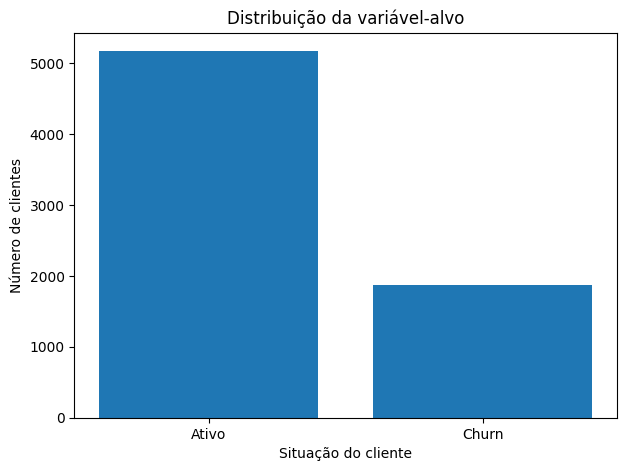

In [14]:
# Distribuição da variável-alvo

churn_counts = contract['Churn'].value_counts().sort_index()

plt.figure(figsize=(7, 5))
plt.bar(['Ativo', 'Churn'], churn_counts.values)

plt.title('Distribuição da variável-alvo')
plt.xlabel('Situação do cliente')
plt.ylabel('Número de clientes')

plt.show()

### Variável-alvo

A variável-alvo do projeto será denominada `Churn`.

Ela será construída a partir da variável `EndDate`:

- `Churn = 0`: cliente sem data de encerramento do contrato e, portanto, ativo na data de referência;
- `Churn = 1`: cliente com uma data de encerramento registrada, indicando cancelamento.

A análise inicial mostra que a maior parte dos clientes permanece ativa, enquanto aproximadamente 26,5% apresentam churn.

Existe, portanto, um desbalanceamento entre as classes que deverá ser considerado posteriormente durante o desenvolvimento e a avaliação dos modelos. A escolha das métricas de avaliação será definida considerando os objetivos de negócio e as orientações obtidas na etapa de esclarecimento do projeto.

## 3. Análise Exploratória dos Dados

Após a análise inicial das quatro fontes de dados e a definição da variável-alvo, será realizada uma exploração mais detalhada das características dos clientes.

Nesta etapa serão investigados:

- possíveis problemas nos tipos de dados;
- características contratuais e financeiras;
- tempo de relacionamento dos clientes com a empresa;
- utilização dos serviços de internet e telefonia;
- distribuição das características entre clientes ativos e clientes que cancelaram;
- possíveis atributos associados ao churn.

Essa análise ajudará a identificar características potencialmente relevantes para a etapa posterior de modelagem.

In [15]:
# Verificando o tipo da variável TotalCharges

print('Tipo de TotalCharges:')
print(contract['TotalCharges'].dtype)

print('\nPrimeiros valores:')
display(contract[['MonthlyCharges', 'TotalCharges']].head(10))

Tipo de TotalCharges:
object

Primeiros valores:


,MonthlyCharges,TotalCharges
0,29.85,29.85
1,56.95,1889.5
2,53.85,108.15
3,42.30,1840.75
4,70.70,151.65
5,99.65,820.5
6,89.10,1949.4
7,29.75,301.9
8,104.80,3046.05
9,56.15,3487.95


In [16]:
# Procurando valores que não podem ser convertidos diretamente para número

total_charges_numeric = pd.to_numeric(
    contract['TotalCharges'],
    errors='coerce'
)

print('Valores que se tornam ausentes após a conversão:')
print(total_charges_numeric.isna().sum())

Valores que se tornam ausentes após a conversão:
11


In [17]:
# Registros com TotalCharges não numérico

contract[
    pd.to_numeric(contract['TotalCharges'], errors='coerce').isna()
]

,customerID,BeginDate,EndDate,Type,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,2020-02-01,No,Two year,Yes,Bank transfer (automatic),52.55,,0
753,3115-CZMZD,2020-02-01,No,Two year,No,Mailed check,20.25,,0
936,5709-LVOEQ,2020-02-01,No,Two year,No,Mailed check,80.85,,0
1082,4367-NUYAO,2020-02-01,No,Two year,No,Mailed check,25.75,,0
1340,1371-DWPAZ,2020-02-01,No,Two year,No,Credit card (automatic),56.05,,0
3331,7644-OMVMY,2020-02-01,No,Two year,No,Mailed check,19.85,,0
3826,3213-VVOLG,2020-02-01,No,Two year,No,Mailed check,25.35,,0
4380,2520-SGTTA,2020-02-01,No,Two year,No,Mailed check,20.00,,0
5218,2923-ARZLG,2020-02-01,No,One year,Yes,Mailed check,19.70,,0
6670,4075-WKNIU,2020-02-01,No,Two year,No,Mailed check,73.35,,0


In [18]:
# Conversão de TotalCharges para tipo numérico

contract['TotalCharges'] = pd.to_numeric(
    contract['TotalCharges'],
    errors='coerce'
)

print(contract['TotalCharges'].dtype)
print('Valores ausentes:', contract['TotalCharges'].isna().sum())

float64
Valores ausentes: 11


### Tratamento inicial de `TotalCharges`

A variável `TotalCharges`, apesar de representar valores monetários, foi inicialmente carregada como uma variável do tipo `object`.

Após sua conversão para formato numérico, alguns registros passaram a apresentar valores ausentes. Esses casos serão investigados antes da definição de uma estratégia de tratamento, evitando a substituição arbitrária de valores sem considerar o contexto dos clientes.

A conversão é necessária para permitir análises estatísticas e para que essa característica possa posteriormente ser utilizada pelos modelos de machine learning.

In [19]:
# Conversão da data de início do contrato

contract['BeginDate'] = pd.to_datetime(contract['BeginDate'])

print(contract['BeginDate'].dtype)

print('\nPeríodo disponível:')
print('Data mais antiga:', contract['BeginDate'].min())
print('Data mais recente:', contract['BeginDate'].max())

datetime64[ns]

Período disponível:
Data mais antiga: 2013-10-01 00:00:00
Data mais recente: 2020-02-01 00:00:00


In [20]:
# Conversão de EndDate para datetime
# Clientes ativos possuem "No", que será convertido para NaT

contract['EndDate_dt'] = pd.to_datetime(
    contract['EndDate'].replace('No', np.nan)
)

contract[['BeginDate', 'EndDate', 'EndDate_dt', 'Churn']].head()

,BeginDate,EndDate,EndDate_dt,Churn
0,2020-01-01,No,NaT,0
1,2017-04-01,No,NaT,0
2,2019-10-01,2019-12-01 00:00:00,2019-12-01,1
3,2016-05-01,No,NaT,0
4,2019-09-01,2019-11-01 00:00:00,2019-11-01,1


In [21]:
# Data de referência informada no projeto

reference_date = pd.Timestamp('2020-02-01')

# Data utilizada para calcular o tempo de relacionamento
contract['FinalDate'] = contract['EndDate_dt'].fillna(reference_date)

# Tempo de contrato em meses
contract['TenureMonths'] = (
    (contract['FinalDate'].dt.year - contract['BeginDate'].dt.year) * 12
    + (contract['FinalDate'].dt.month - contract['BeginDate'].dt.month)
)

contract[
    ['BeginDate', 'EndDate', 'Churn', 'TenureMonths']
].head(10)

,BeginDate,EndDate,Churn,TenureMonths
0,2020-01-01,No,0,1
1,2017-04-01,No,0,34
2,2019-10-01,2019-12-01 00:00:00,1,2
3,2016-05-01,No,0,45
4,2019-09-01,2019-11-01 00:00:00,1,2
5,2019-03-01,2019-11-01 00:00:00,1,8
6,2018-04-01,No,0,22
7,2019-04-01,No,0,10
8,2017-07-01,2019-11-01 00:00:00,1,28
9,2014-12-01,No,0,62


In [22]:
# Estatísticas descritivas do tempo de relacionamento

contract['TenureMonths'].describe()

count   7043.00
mean      32.37
std       24.56
min        0.00
25%        9.00
50%       29.00
75%       55.00
max       72.00
Name: TenureMonths, dtype: float64

In [23]:
contract.groupby('Churn')['TenureMonths'].agg(
    ['count', 'mean', 'median', 'std', 'min', 'max']
)

,count,mean,median,std,min,max
Churn,,,,,,
0,5174,37.57,38,24.11,0,72
1,1869,17.98,10,19.53,1,72


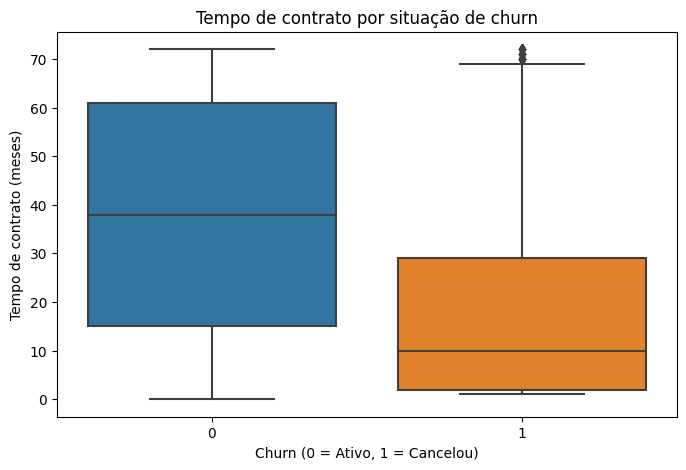

In [24]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=contract,
    x='Churn',
    y='TenureMonths'
)

plt.title('Tempo de contrato por situação de churn')
plt.xlabel('Churn (0 = Ativo, 1 = Cancelou)')
plt.ylabel('Tempo de contrato (meses)')

plt.show()

In [25]:
contract.groupby('Churn')['MonthlyCharges'].agg(
    ['count', 'mean', 'median', 'std']
)


,count,mean,median,std
Churn,,,,
0,5174,61.27,64.43,31.09
1,1869,74.44,79.65,24.67


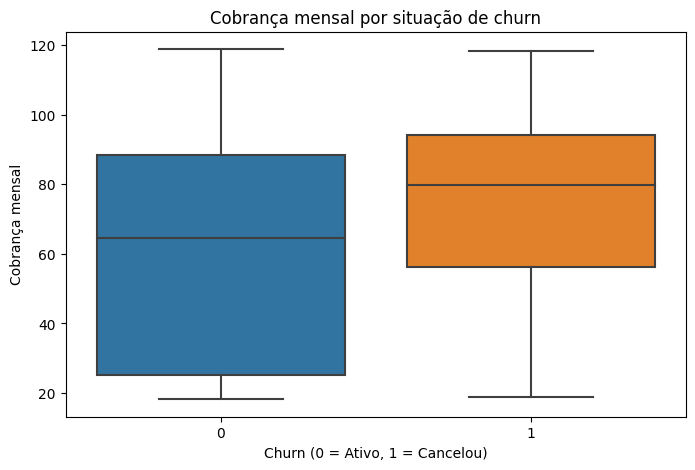

In [26]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=contract,
    x='Churn',
    y='MonthlyCharges'
)

plt.title('Cobrança mensal por situação de churn')
plt.xlabel('Churn (0 = Ativo, 1 = Cancelou)')
plt.ylabel('Cobrança mensal')

plt.show()

In [27]:
contract.groupby('Churn')['TotalCharges'].agg(
    ['count', 'mean', 'median', 'std']
)

,count,mean,median,std
Churn,,,,
0,5163,2555.34,1683.60,2329.46
1,1869,1531.80,703.55,1890.82


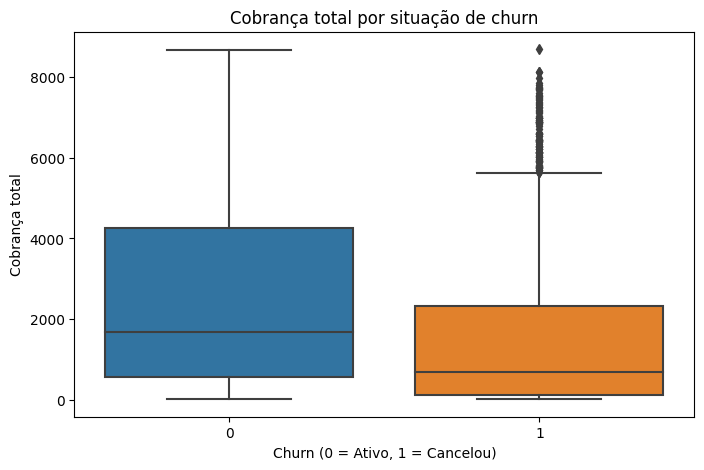

In [28]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=contract,
    x='Churn',
    y='TotalCharges'
)

plt.title('Cobrança total por situação de churn')
plt.xlabel('Churn (0 = Ativo, 1 = Cancelou)')
plt.ylabel('Cobrança total')

plt.show()

### Características financeiras e tempo de relacionamento

Foram analisadas as distribuições de `TenureMonths`, `MonthlyCharges` e `TotalCharges` entre clientes ativos e clientes que apresentaram churn.

As diferenças observadas entre os grupos serão consideradas na seleção preliminar de atributos para a modelagem. Entretanto, nesta etapa essas relações são interpretadas como associações exploratórias, e não como evidência de causalidade.

## 4. Integração das fontes de dados

Como as informações dos clientes estão distribuídas entre quatro arquivos, será construída uma base analítica única utilizando `customerID` como chave de integração.

A tabela de contratos será utilizada como base principal, pois contém os 7.043 clientes e as informações necessárias para definição da variável-alvo.

Será utilizado `left join` para preservar todos os clientes presentes na base contratual. Dessa forma, clientes que não possuem determinado serviço não serão excluídos da análise.

In [29]:
# Integração das quatro fontes de dados

data = (
    contract
    .merge(personal, on='customerID', how='left')
    .merge(internet, on='customerID', how='left')
    .merge(phone, on='customerID', how='left')
)

print('Dimensão da base integrada:', data.shape)

display(data.head())

Dimensão da base integrada: (7043, 24)


,customerID,BeginDate,EndDate,Type,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,EndDate_dt,FinalDate,TenureMonths,gender,SeniorCitizen,Partner,Dependents,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,MultipleLines
0,7590-VHVEG,2020-01-01,No,Month-to-month,Yes,Electronic check,29.85,29.85,0,NaT,2020-02-01,1,Female,0,Yes,No,DSL,No,Yes,No,No,No,No,NaN
1,5575-GNVDE,2017-04-01,No,One year,No,Mailed check,56.95,1889.50,0,NaT,2020-02-01,34,Male,0,No,No,DSL,Yes,No,Yes,No,No,No,No
2,3668-QPYBK,2019-10-01,2019-12-01 00:00:00,Month-to-month,Yes,Mailed check,53.85,108.15,1,2019-12-01,2019-12-01,2,Male,0,No,No,DSL,Yes,Yes,No,No,No,No,No
3,7795-CFOCW,2016-05-01,No,One year,No,Bank transfer (automatic),42.30,1840.75,0,NaT,2020-02-01,45,Male,0,No,No,DSL,Yes,No,Yes,Yes,No,No,NaN
4,9237-HQITU,2019-09-01,2019-11-01 00:00:00,Month-to-month,Yes,Electronic check,70.70,151.65,1,2019-11-01,2019-11-01,2,Female,0,No,No,Fiber optic,No,No,No,No,No,No,No


In [30]:
data.shape[0]

7043

In [31]:
print('Número de clientes:', len(data))
print('customerID únicos:', data['customerID'].nunique())
print('Duplicados:', data['customerID'].duplicated().sum())

Número de clientes: 7043
customerID únicos: 7043
Duplicados: 0


In [32]:
# Valores ausentes após a integração

missing = pd.DataFrame({
    'Ausentes': data.isna().sum(),
    'Percentual (%)': data.isna().mean() * 100
})

missing = missing[missing['Ausentes'] > 0].sort_values(
    'Percentual (%)',
    ascending=False
)

display(missing)

,Ausentes,Percentual (%)
EndDate_dt,5174,73.46
InternetService,1526,21.67
OnlineSecurity,1526,21.67
OnlineBackup,1526,21.67
DeviceProtection,1526,21.67
TechSupport,1526,21.67
StreamingTV,1526,21.67
StreamingMovies,1526,21.67
MultipleLines,682,9.68
TotalCharges,11,0.16


### Valores ausentes após a integração

A integração das tabelas gera valores ausentes principalmente nas variáveis relacionadas aos serviços de internet e telefonia.

Esses valores não devem ser interpretados automaticamente como falhas de coleta. Como nem todos os clientes utilizam todos os serviços oferecidos pela Interconnect, a ausência de registros nessas tabelas pode indicar que determinado serviço não foi contratado.

Por esse motivo, esses casos serão tratados de forma semântica durante a preparação dos dados, distinguindo a ausência de contratação de um serviço de um valor genuinamente desconhecido.

### Tratamento dos valores ausentes em `TotalCharges`

Foram identificados 11 registros sem valor numérico em `TotalCharges`. Esses casos correspondem a clientes com tempo de relacionamento igual a zero, indicando contratos recém-iniciados que ainda não acumularam cobranças.

Por esse motivo, os valores ausentes de `TotalCharges` serão preenchidos com zero. Essa abordagem preserva os registros e representa adequadamente a ausência de cobranças acumuladas para esses clientes.

In [33]:
# Preenchimento dos TotalCharges ausentes

data['TotalCharges'] = data['TotalCharges'].fillna(0)

print('Valores ausentes em TotalCharges:')
print(data['TotalCharges'].isna().sum())

Valores ausentes em TotalCharges:
0


In [34]:
# Função para analisar a taxa de churn por categoria

def churn_by_category(data, column):
    result = (
        data.groupby(column)['Churn']
        .agg(['count', 'sum', 'mean'])
        .rename(columns={
            'count': 'Clientes',
            'sum': 'Churns',
            'mean': 'Taxa_Churn'
        })
    )
    
    result['Taxa_Churn (%)'] = result['Taxa_Churn'] * 100
    
    return result.drop(columns='Taxa_Churn').sort_values(
        'Taxa_Churn (%)',
        ascending=False
    )
    

In [35]:
churn_by_category(data, 'Type')

,Clientes,Churns,Taxa_Churn (%)
Type,,,
Month-to-month,3875,1655,42.71
One year,1473,166,11.27
Two year,1695,48,2.83


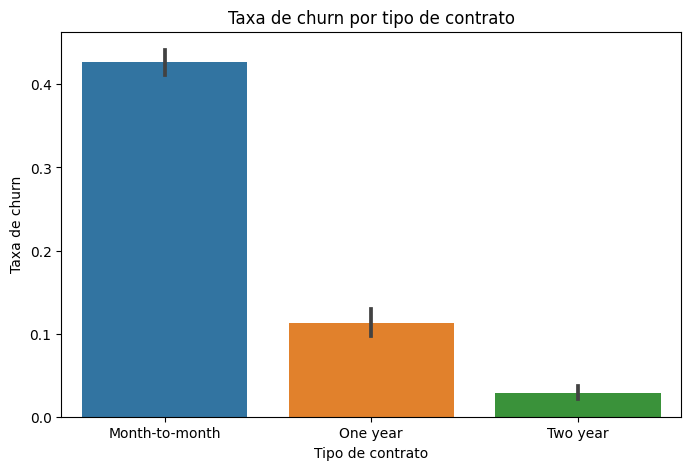

In [36]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=data,
    x='Type',
    y='Churn'
)

plt.title('Taxa de churn por tipo de contrato')
plt.xlabel('Tipo de contrato')
plt.ylabel('Taxa de churn')

plt.show()

In [37]:
churn_by_category(data, 'PaymentMethod')

,Clientes,Churns,Taxa_Churn (%)
PaymentMethod,,,
Electronic check,2365,1071,45.29
Mailed check,1612,308,19.11
Bank transfer (automatic),1544,258,16.71
Credit card (automatic),1522,232,15.24


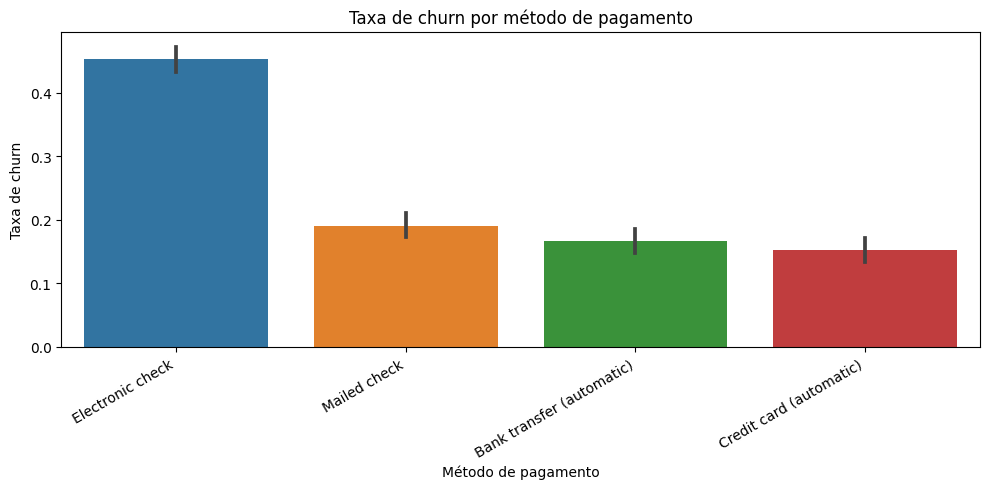

In [38]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=data,
    x='PaymentMethod',
    y='Churn'
)

plt.title('Taxa de churn por método de pagamento')
plt.xlabel('Método de pagamento')
plt.ylabel('Taxa de churn')

plt.xticks(rotation=30, ha='right')

plt.tight_layout()
plt.show()

In [39]:
churn_by_category(data, 'PaperlessBilling')

,Clientes,Churns,Taxa_Churn (%)
PaperlessBilling,,,
Yes,4171,1400,33.57
No,2872,469,16.33


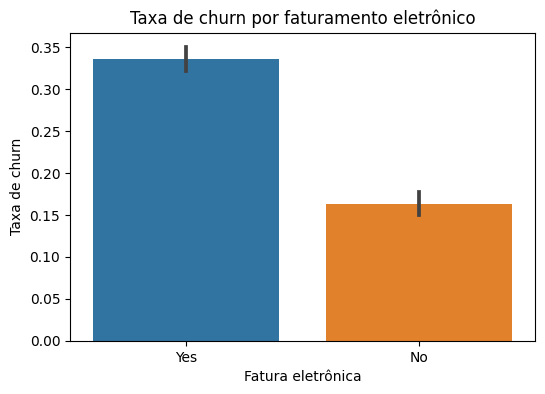

In [40]:
plt.figure(figsize=(6, 4))

sns.barplot(
    data=data,
    x='PaperlessBilling',
    y='Churn'
)

plt.title('Taxa de churn por faturamento eletrônico')
plt.xlabel('Fatura eletrônica')
plt.ylabel('Taxa de churn')

plt.show()

In [41]:
# Representando clientes sem serviço de internet

data['InternetService'] = data['InternetService'].fillna('No internet')

churn_by_category(data, 'InternetService')

,Clientes,Churns,Taxa_Churn (%)
InternetService,,,
Fiber optic,3096,1297,41.89
DSL,2421,459,18.96
No internet,1526,113,7.40


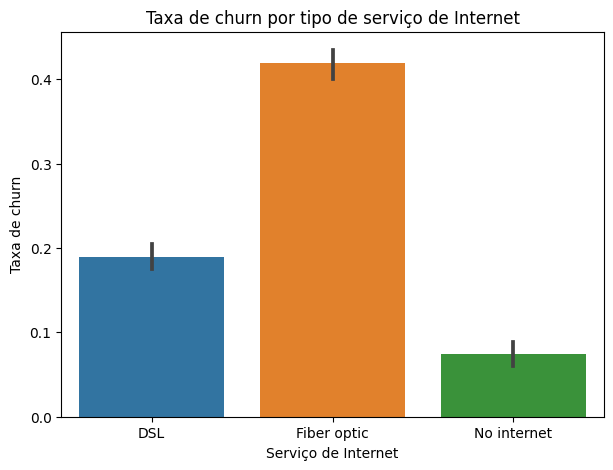

In [42]:
plt.figure(figsize=(7, 5))

sns.barplot(
    data=data,
    x='InternetService',
    y='Churn'
)

plt.title('Taxa de churn por tipo de serviço de Internet')
plt.xlabel('Serviço de Internet')
plt.ylabel('Taxa de churn')

plt.show()

In [43]:
internet_features = [
    'OnlineSecurity',
    'OnlineBackup',
    'DeviceProtection',
    'TechSupport',
    'StreamingTV',
    'StreamingMovies'
]

# Ausência na tabela internet significa que o cliente não possui Internet
data[internet_features] = data[internet_features].fillna('No internet')

for column in internet_features:
    print(f'\n{column}')
    display(churn_by_category(data, column))


OnlineSecurity


,Clientes,Churns,Taxa_Churn (%)
OnlineSecurity,,,
No,3498,1461,41.77
Yes,2019,295,14.61
No internet,1526,113,7.40



OnlineBackup


,Clientes,Churns,Taxa_Churn (%)
OnlineBackup,,,
No,3088,1233,39.93
Yes,2429,523,21.53
No internet,1526,113,7.40



DeviceProtection


,Clientes,Churns,Taxa_Churn (%)
DeviceProtection,,,
No,3095,1211,39.13
Yes,2422,545,22.50
No internet,1526,113,7.40


... (2 outputs left out)


StreamingTV


,Clientes,Churns,Taxa_Churn (%)
StreamingTV,,,
No,2810,942,33.52
Yes,2707,814,30.07
No internet,1526,113,7.40



StreamingMovies


,Clientes,Churns,Taxa_Churn (%)
StreamingMovies,,,
No,2785,938,33.68
Yes,2732,818,29.94
No internet,1526,113,7.40


In [44]:
data['MultipleLines'] = data['MultipleLines'].fillna('No phone')

churn_by_category(data, 'MultipleLines')

,Clientes,Churns,Taxa_Churn (%)
MultipleLines,,,
Yes,2971,850,28.61
No,3390,849,25.04
No phone,682,170,24.93


In [45]:
personal_features = [
    'gender',
    'SeniorCitizen',
    'Partner',
    'Dependents'
]

for column in personal_features:
    print(f'\n{column}')
    display(churn_by_category(data, column))


gender


,Clientes,Churns,Taxa_Churn (%)
gender,,,
Female,3488,939,26.92
Male,3555,930,26.16



SeniorCitizen


,Clientes,Churns,Taxa_Churn (%)
SeniorCitizen,,,
1,1142,476,41.68
0,5901,1393,23.61



Partner


,Clientes,Churns,Taxa_Churn (%)
Partner,,,
No,3641,1200,32.96
Yes,3402,669,19.66



Dependents


,Clientes,Churns,Taxa_Churn (%)
Dependents,,,
No,4933,1543,31.28
Yes,2110,326,15.45


## Tabela consolidada das principais taxas

In [46]:
categorical_features = [
    'Type',
    'PaymentMethod',
    'PaperlessBilling',
    'InternetService',
    'OnlineSecurity',
    'OnlineBackup',
    'DeviceProtection',
    'TechSupport',
    'StreamingTV',
    'StreamingMovies',
    'MultipleLines',
    'gender',
    'SeniorCitizen',
    'Partner',
    'Dependents'
]

for column in categorical_features:
    print('\n' + '=' * 50)
    print(column)
    print('=' * 50)
    display(churn_by_category(data, column))


Type


,Clientes,Churns,Taxa_Churn (%)
Type,,,
Month-to-month,3875,1655,42.71
One year,1473,166,11.27
Two year,1695,48,2.83



PaymentMethod


,Clientes,Churns,Taxa_Churn (%)
PaymentMethod,,,
Electronic check,2365,1071,45.29
Mailed check,1612,308,19.11
Bank transfer (automatic),1544,258,16.71
Credit card (automatic),1522,232,15.24



PaperlessBilling


,Clientes,Churns,Taxa_Churn (%)
PaperlessBilling,,,
Yes,4171,1400,33.57
No,2872,469,16.33


... (20 outputs left out)


Partner


,Clientes,Churns,Taxa_Churn (%)
Partner,,,
No,3641,1200,32.96
Yes,3402,669,19.66



Dependents


,Clientes,Churns,Taxa_Churn (%)
Dependents,,,
No,4933,1543,31.28
Yes,2110,326,15.45


## Verificar o período dos cancelamentos

In [47]:
# Verificando o período dos cancelamentos registrados

cancel_dates = contract.loc[
    contract['EndDate'] != 'No',
    'EndDate'
].copy()

cancel_dates = pd.to_datetime(cancel_dates)

print('Primeiro cancelamento registrado:', cancel_dates.min())
print('Último cancelamento registrado:', cancel_dates.max())
print('Quantidade de cancelamentos registrados:', len(cancel_dates))

Primeiro cancelamento registrado: 2019-10-01 00:00:00
Último cancelamento registrado: 2020-01-01 00:00:00
Quantidade de cancelamentos registrados: 1869


### Período dos cancelamentos registrados

Foram identificados 1.869 cancelamentos, com datas de encerramento entre **1º de outubro de 2019 e 1º de janeiro de 2020**. Portanto, os cancelamentos registrados estão concentrados em um período recente de quatro meses de referência, embora a base contenha clientes com contratos iniciados vários anos antes.

Essa concentração representa uma limitação importante dos dados. Apenas com as informações disponíveis não é possível determinar se não ocorreram cancelamentos antes de outubro de 2019 ou se cancelamentos anteriores não foram registrados na base fornecida.

Essa questão deverá ser considerada na interpretação do histórico de churn e, principalmente, na construção de características relacionadas ao tempo de relacionamento dos clientes.

### Prevenção de vazamento de dados

Algumas variáveis utilizadas durante a análise exploratória não poderão ser utilizadas diretamente como atributos preditores.

Em particular, `EndDate` e `EndDate_dt` contêm informação direta sobre o encerramento do contrato e foram utilizadas para construir a própria variável-alvo `Churn`. Sua inclusão no treinamento produziria vazamento de dados (*data leakage*), permitindo que o modelo tivesse acesso indireto à resposta que deveria prever.

A variável `FinalDate` também foi criada utilizando a data de encerramento dos clientes que apresentaram churn e, portanto, não deverá ser utilizada como preditor.

Essas variáveis serão removidas antes da preparação dos dados para modelagem.

## Conclusões da Análise Exploratória de Dados

A análise exploratória revelou padrões relevantes associados ao cancelamento dos contratos. A base integrada contém 7.043 clientes, dos quais 1.869 apresentaram churn e 5.174 permaneceram ativos.

Um dos fatores mais associados ao churn foi o **tipo de contrato**. Clientes com contratos mensais (`Month-to-month`) apresentaram taxa de churn de **42,71%**, enquanto clientes com contratos de um ano apresentaram **11,27%** e aqueles com contratos de dois anos apenas **2,83%**. Esse resultado sugere uma forte associação entre maior compromisso contratual e maior retenção.

O **método de pagamento** também apresentou diferenças importantes. Clientes que utilizam `Electronic check` tiveram taxa de churn de **45,29%**, consideravelmente superior às taxas observadas para cartão de crédito automático (**15,24%**) e transferência bancária automática (**16,71%**).

Em relação ao serviço de Internet, clientes com **fibra óptica** apresentaram churn de **41,89%**, enquanto clientes DSL apresentaram **18,96%**. Clientes sem serviço de Internet tiveram a menor taxa, **7,40%**. Esse resultado indica que o grupo de clientes de fibra óptica merece atenção especial durante a modelagem e na investigação das possíveis causas de cancelamento.

Os serviços adicionais também mostraram associações relevantes. Clientes sem `OnlineSecurity` apresentaram churn de **41,77%**, contra **14,61%** entre aqueles que possuem o serviço. Para `TechSupport`, as taxas foram **41,64%** entre clientes sem suporte e **15,17%** entre clientes com suporte. Resultados semelhantes, embora menos intensos, foram observados para `OnlineBackup` e `DeviceProtection`.

As características pessoais também revelaram alguns padrões. Clientes classificados como idosos (`SeniorCitizen = 1`) apresentaram churn de **41,68%**, comparado a **23,61%** entre os demais clientes. Clientes sem parceiro apresentaram churn de **32,96%**, contra **19,66%** entre aqueles com parceiro. Clientes sem dependentes apresentaram taxa de **31,28%**, enquanto aqueles com dependentes apresentaram **15,45%**.

Por outro lado, algumas características apresentaram pouca diferença entre os grupos. A taxa de churn foi de **26,92%** entre mulheres e **26,16%** entre homens, indicando que gênero isoladamente provavelmente possui baixo poder discriminativo. A presença de múltiplas linhas telefônicas também apresentou diferenças relativamente pequenas.

As variáveis numéricas reforçam esses padrões. Clientes que cancelaram permaneceram em média aproximadamente **18 meses**, enquanto clientes ativos apresentaram média de aproximadamente **37,6 meses** de relacionamento. Além disso, clientes que cancelaram apresentaram cobrança mensal média mais elevada, aproximadamente **74,44**, contra **61,27** entre os clientes ativos.

Em conjunto, os resultados sugerem que características relacionadas ao **tipo de contrato, método de pagamento, serviço de Internet, serviços adicionais, tempo de relacionamento e cobrança mensal** apresentam maior potencial para auxiliar na previsão de churn.

Essas relações são observacionais e não devem ser interpretadas como relações causais. Na etapa de modelagem, diferentes algoritmos serão comparados para verificar quais características contribuem efetivamente para a capacidade preditiva do modelo.

## 5. Perguntas de esclarecimento

Após a análise exploratória dos dados, algumas questões precisam ser esclarecidas antes do desenvolvimento e da avaliação dos modelos:

1. **Qual métrica deve ser priorizada na avaliação do modelo de churn?**  
   Considerando o objetivo de identificar clientes com risco de cancelamento, é importante saber se a empresa deseja priorizar a identificação do maior número possível de clientes que podem cancelar ou manter um equilíbrio entre diferentes tipos de erro.

2. **Existe um custo diferente associado aos falsos positivos e falsos negativos?**  
   Por exemplo, deixar de identificar um cliente que realmente irá cancelar pode ter um impacto diferente de oferecer uma ação de retenção a um cliente que não pretendia cancelar.

3. **Com que antecedência a empresa pretende identificar um cliente com risco de churn?**  
   Essa informação pode influenciar quais variáveis estarão disponíveis no momento em que o modelo for utilizado.

4. **As informações disponíveis representam exatamente os dados que estarão acessíveis no momento da previsão em produção?**  
   Essa confirmação é importante para evitar o uso de informações que só se tornam conhecidas após o cancelamento do contrato.

5. **Como as previsões do modelo serão utilizadas pela equipe de retenção?**  
   Saber se haverá campanhas, ofertas ou contatos direcionados aos clientes classificados como de maior risco pode ajudar a definir a estratégia de avaliação e o limiar de decisão do modelo.

6. **Os cancelamentos anteriores ao primeiro `EndDate` registrado não ocorreram ou não foram incluídos nesta base de dados?**  
   As datas de encerramento disponíveis estão concentradas em um período recente, embora existam clientes com contratos iniciados vários anos antes. Esse esclarecimento é importante para interpretar corretamente o histórico de churn e o tempo de relacionamento dos clientes.

## 6. Plano geral de resolução da tarefa

Com base na análise exploratória inicial, o desenvolvimento do projeto seguirá as seguintes etapas:

### 1. Preparação e integração dos dados
As diferentes fontes de dados serão integradas por meio do identificador `customerID`. Os tipos de dados, valores ausentes e variáveis categóricas serão tratados de forma adequada para a etapa de modelagem.

### 2. Engenharia e seleção de características
Serão criadas ou selecionadas características relevantes para representar o comportamento e o histórico dos clientes. Também serão removidas variáveis que possam causar vazamento de dados ou que não estejam disponíveis no momento da previsão.

### 3. Treinamento de modelos de classificação
Inicialmente será treinado um `DummyClassifier` como modelo básico de referência. Em seguida, serão comparados modelos de Regressão Logística, Random Forest e um algoritmo de boosting, como LightGBM, utilizando `random_state=12345` quando aplicável para garantir a reprodutibilidade dos experimentos.

### 4. Validação, ajuste e comparação dos modelos
A divisão entre treinamento e teste será realizada de forma estratificada para preservar a proporção da variável-alvo. A AUC-ROC será utilizada como principal métrica de comparação, com métricas complementares como acurácia, precisão, recall e F1-score. O ajuste de hiperparâmetros será realizado por validação cruzada utilizando apenas os dados de treinamento.

### 5. Seleção e análise do modelo final
Após a comparação e o ajuste dos modelos, o algoritmo com melhor desempenho de validação será selecionado. Seu limiar de classificação será analisado e o modelo será avaliado uma única vez no conjunto de teste, seguido da análise da importância das características e da interpretação dos resultados no contexto de retenção de clientes.